# Codec Test Pipeline

In [ ]:
# imports
from pathlib import Path
from PIL import Image
from tempfile import TemporaryFile
from codec import Codec, RLE, ZigZag, DCT, Quantisation
import json
import numpy as np
import matplotlib.pyplot as plt
import random

In [7]:
def display_image(img, cmap: str = None, title: str = None, 
                  axes: bool = True, figsize=(4, 4),
                  xlabel: str = None, ylabel: str = None, xticks: list = None, yticks: list = None, ax=None):
    
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
        
    ax.imshow(img, cmap=cmap)

    if title is not None:
        ax.set_title(title)

    if xlabel is not None:
        ax.set_xlabel(xlabel)

    if ylabel is not None:
        ax.set_ylabel(ylabel)

    if not axes:
        ax.axis('off')
        
    if xticks is not None:
        ax.set_xticks(xticks)
        
    if yticks is not None:
        ax.set_yticks(yticks)
        
    return ax

In [8]:
def inputs(read_img = False, read_output_dir_path = False, read_q_step = False, read_block_size = False):
    
    inputs = {}
    
    # read the image path
    if read_img:
        img_path = Path(input("Enter the image path: ").strip()).expanduser()

        if not img_path.is_file():
            raise FileNotFoundError(f"Image not found: {img_path}")
    else:
        img_path = ""
    
    inputs["img_path"] = img_path
    
    # rad the folder input where compressed images will be stored
    while read_output_dir_path:
        try:
            folder_text = input("Enter the output folder: ").strip()

            if not folder_text:
                raise ValueError("The folder path cannot be empty.")
            
            break

        except (OSError, ValueError, RuntimeError) as error:
            print(f"Cannot use this folder: {error}")
            print("Please enter another folder path.")
    if not read_output_dir_path:
        folder_text = "compressed_images"
    output_dir = Path(folder_text).expanduser()
    output_dir.mkdir(parents=True, exist_ok=True)
    inputs["output_dir"] = output_dir

    # read the q_step input
    while read_q_step:
        try:
            q_step = int(input("Enter value for quantisation step (e.g. 32): "))

            if q_step <= 0:
                raise ValueError

            break
        
        except ValueError:
            print("Invalid q_step. Enter a positive integer like 8 or 32.")
    if not read_q_step:
        q_step = 32
    inputs["q_step"] = q_step

    # read the block size input
    while read_block_size:
        try:
            block_size = int(input("Enter block size (positive integer e.g. 8): "))

            if block_size <= 0:
                raise ValueError

            break

        except ValueError:
            print("Enter a valid block size.")
    if not read_block_size:
        block_size = 8
    inputs["block_size"] = block_size
    
    return inputs


In [13]:
def test_pipeline(settings):
    
     # unpack inputs
    img_path = settings["img_path"]
    output_dir = settings["output_dir"]
    q_step = settings["q_step"]
    block_size = settings["block_size"]

    # display the image
    with Image.open(img_path) as source:
        img = source.convert("RGB")

    img_array = np.array(img)

    print("Selected Image: ")
    display_image(img, axes=False)
    plt.show()

    # configure Codec
    codec = Codec(stages=[DCT(), Quantisation(q_steps=q_step), ZigZag(), RLE()], block_size=block_size, output_dir=output_dir,)
    output_filename = f"{img_path.stem}_compressed.json"

    # perform compression
    codec.compress(img, output_file=output_filename)

    # verify compressed image was created
    compressed_file_path = codec.output_dir / f"{output_filename}"

    if not compressed_file_path.is_file():
        raise FileNotFoundError("Compressed file was not created")

    if compressed_file_path.stat().st_size == 0:
        raise ValueError("Compressed file is empty")

    print("Verified: The compressed file exists.")
    print("Verified: The compressed file is not empty.")

    # perform decompression
    with compressed_file_path.open('r', encoding="utf-8") as file:
        compressed_image = json.load(file)

    decompressed_image = codec.decompress(compressed_image)

    # verify decompressed image shape and type
    assert decompressed_image.shape == img_array.shape
    assert decompressed_image.dtype == img_array.dtype

    # display the reconstructed image
    display_image(Image.fromarray(decompressed_image), axes=False)
    plt.show()

    # calculate statistics
    raw_image_size = img_array.nbytes
    compressed_image_size = compressed_file_path.stat().st_size

    height, width = img_array.shape[:2]
    bits_per_pixel = compressed_image_size * 8 / (height * width)
    compression_ratio = raw_image_size / compressed_image_size

    difference = (img_array.astype(np.float64) - decompressed_image.astype(np.float64))
    mse = float(np.mean(difference ** 2))
    psnr = np.inf if mse == 0 else 10 * np.log10(255**2 / mse)

    # display the stats
    print("Statistics:")
    print(f"Block size: {block_size}")
    print(f"Quantisation step: {q_step}")
    print(f"Raw image size: {raw_image_size} bytes")
    print(f"Compressed file size: {compressed_image_size} bytes")
    print(f"Raw to compressed image ratio: {compression_ratio}")
    print(f"Bits per pixel: {bits_per_pixel}")
    print(f"Mean squared error: {mse}")
    print(f"PSNR: {psnr}")


## Seed Input

## Empty Input

## Custom File Input

Selected Image: 


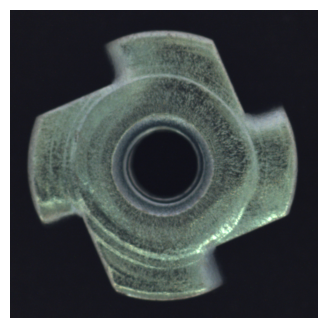

Encoded image saved to: compressed_image/211_compressed.json
Verified: The compressed file exists.
Verified: The compressed file is not empty.


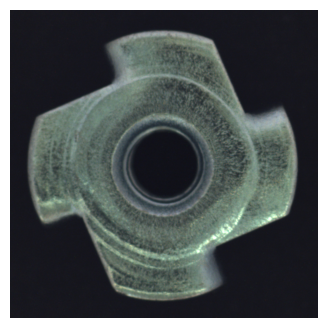

Statistics:
Block size: 8
Quantisation step: 2
Raw image size: 1470000 bytes
Compressed file size: 4906097 bytes
Raw to compressed image ratio: 0.29962717818257567
Bits per pixel: 80.09954285714285
Mean squared error: 0.3560544217687075
PSNR: 52.61563977312225


In [15]:
# read inputs
settings = inputs(read_img = True, read_output_dir_path = True, read_q_step = True, read_block_size = True)
test_pipeline(settings=settings)